# InflationCast
## Forecasting India’s Consumer Price Inflation Using Historical CPI Dynamics

**Applied Machine Learning Capstone — Regression**  
**Team:** Brij Nandan Rawat (Batch 10), Suvansh Bansal (Batch 10)

### Problem Statement
Forecast **next month’s All-India CPI Combined year-on-year inflation (%)** using only historical CPI/inflation information available up to the current month.

### Why this design?
It avoids data leakage, uses an authentic official CPI series, and keeps the project explainable for implementation and viva.

**Primary data source:** NSO, Ministry of Statistics & Programme Implementation (MoSPI), Government of India.

Sources used to compile the supplied CSV:
- https://des.delhi.gov.in/sites/default/files/DES/universal-tab/price_indices_2024_25.pdf (Table 3.2(ii), NSO/MoSPI source)
- https://www.pib.gov.in/PressReleasePage.aspx?PRID=2227012 (MoSPI/PIB CPI base revision release and 2025/2026 values)
- https://esankhyiki.mospi.gov.in/catalogue-main/catalogue?product=CPI

> The model is a forecasting exercise, not an official MoSPI forecast.


## 1. Setup


In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")
SEED = 42
TEST_MONTHS = 18
plt.rcParams["figure.figsize"] = (10, 4.5)


## 2. Load and Validate the Authentic Dataset
The dataset contains monthly **All-India Combined General CPI index** values. Inflation is calculated as the year-on-year percentage change:

$$Inflation_t = (CPI_t/CPI_{t-12}-1)\times100$$

No synthetic/demo fallback is used. If the real CSV is missing, the notebook stops.


In [2]:
candidates = [Path("data/raw/India_CPI_Inflation_2013_2025.csv"), Path("India_CPI_Inflation_2013_2025.csv"), Path("/mnt/data/India_CPI_Inflation_2013_2025.csv")]
DATA_PATH = next((p for p in candidates if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("India_CPI_Inflation_2013_2025.csv not found. Keep the CSV beside this notebook.")

df = pd.read_csv(DATA_PATH, parse_dates=["date"]).sort_values("date")
print(f"Rows: {len(df)} | {df.date.min():%b %Y} to {df.date.max():%b %Y}")
print("Duplicate months:", df["date"].duplicated().sum())
print("Missing values:", df.isna().sum(), sep="\n")
display(df.head())
display(df.tail())


Rows: 156 | Jan 2013 to Dec 2025
Duplicate months: 0
Missing values:
date                  0
cpi_index             0
base_year             0
source                0
inflation_yoy_pct    12
dtype: int64


,date,cpi_index,base_year,source,inflation_yoy_pct
0,2013-01-01,104.6,2012=100,Govt of NCT Delhi DES / NSO-MoSPI,NaN
1,2013-02-01,105.3,2012=100,Govt of NCT Delhi DES / NSO-MoSPI,NaN
2,2013-03-01,105.5,2012=100,Govt of NCT Delhi DES / NSO-MoSPI,NaN
3,2013-04-01,106.1,2012=100,Govt of NCT Delhi DES / NSO-MoSPI,NaN
4,2013-05-01,106.9,2012=100,Govt of NCT Delhi DES / NSO-MoSPI,NaN


,date,cpi_index,base_year,source,inflation_yoy_pct
151,2025-08-01,197.0,2012=100,NSO-MoSPI,2.073
152,2025-09-01,197.0,2012=100,NSO-MoSPI,1.442
153,2025-10-01,197.3,2012=100,NSO-MoSPI,0.254
154,2025-11-01,197.9,2012=100,NSO-MoSPI,0.712
155,2025-12-01,198.0,2012=100,NSO-MoSPI,1.331


## 3. Exploratory Data Analysis


,cpi_index,inflation_yoy_pct
count,156.000,144.000
mean,150.054,4.907
std,27.461,1.699
min,104.600,0.254
25%,127.125,3.681
50%,143.550,5.002
75%,175.400,6.027
max,198.000,8.604


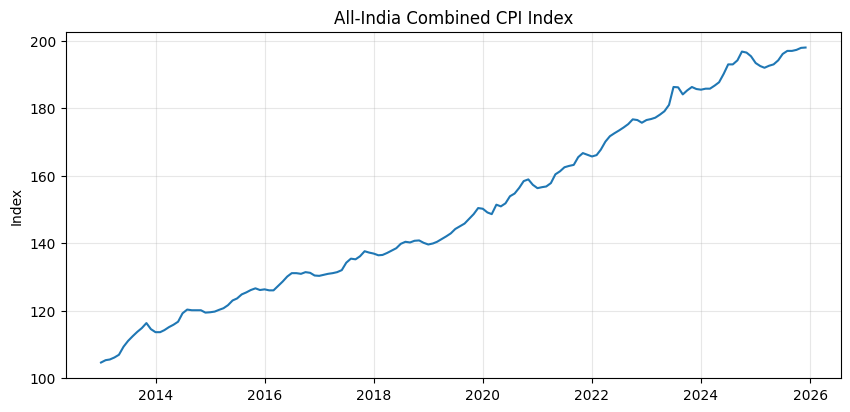

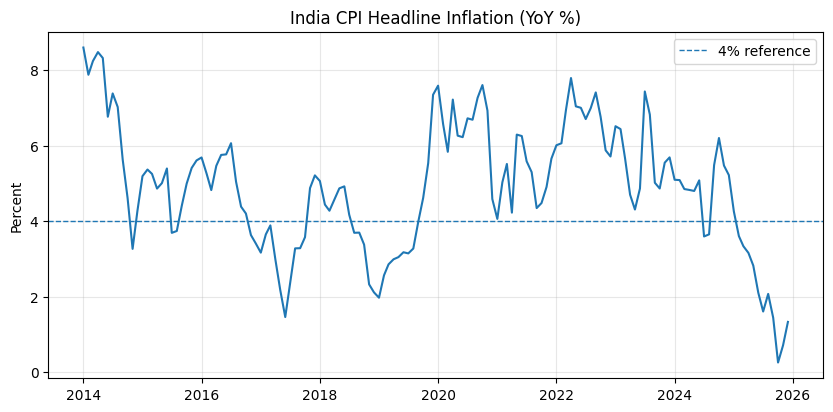

In [3]:
display(df[["cpi_index","inflation_yoy_pct"]].describe().round(3))

fig, ax = plt.subplots(figsize=(10,4.5))
ax.plot(df.date, df.cpi_index)
ax.set_title("All-India Combined CPI Index")
ax.set_ylabel("Index")
ax.grid(alpha=.3)
plt.show()

plot_df=df.dropna(subset=["inflation_yoy_pct"])
fig, ax = plt.subplots(figsize=(10,4.5))
ax.plot(plot_df.date, plot_df.inflation_yoy_pct)
ax.axhline(4, ls="--", lw=1, label="4% reference")
ax.set_title("India CPI Headline Inflation (YoY %)")
ax.set_ylabel("Percent")
ax.legend(); ax.grid(alpha=.3); plt.show()


IQR outlier bounds: 0.16% to 9.55%


,date,inflation_yoy_pct


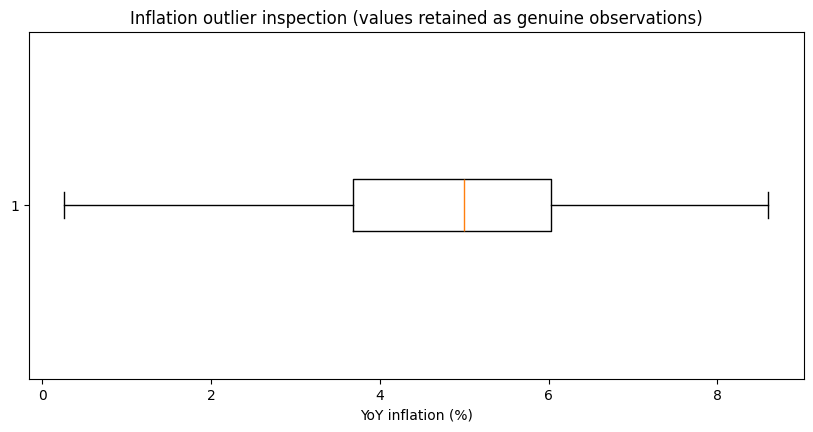

In [4]:
# Outlier inspection: do not automatically delete economic shocks.
q1, q3 = plot_df.inflation_yoy_pct.quantile([.25,.75])
iqr=q3-q1
lo, hi=q1-1.5*iqr, q3+1.5*iqr
outliers=plot_df[(plot_df.inflation_yoy_pct<lo)|(plot_df.inflation_yoy_pct>hi)][["date","inflation_yoy_pct"]]
print(f"IQR outlier bounds: {lo:.2f}% to {hi:.2f}%")
display(outliers)
plt.boxplot(plot_df.inflation_yoy_pct, vert=False)
plt.title("Inflation outlier inspection (values retained as genuine observations)")
plt.xlabel("YoY inflation (%)"); plt.show()


### EDA interpretation
Potential outliers are **retained** unless there is evidence of a data error. Large inflation movements can represent genuine economic shocks; deleting them simply because they are unusual would remove useful information.


## 4. Feature Engineering — No Future Information


In [5]:
d=df.dropna(subset=["inflation_yoy_pct"]).copy().set_index("date")
infl=d["inflation_yoy_pct"]
X=pd.DataFrame(index=d.index)
X["infl_t"]=infl
for lag in [1,2,3,6,12]: X[f"infl_lag{lag}"]=infl.shift(lag)
X["roll3"]=infl.rolling(3).mean()
X["roll6"]=infl.rolling(6).mean()
X["change1"]=infl.diff(1)
X["cpi_mom_pct"]=d.cpi_index.pct_change()*100
X["month_sin"]=np.sin(2*np.pi*X.index.month/12)
X["month_cos"]=np.cos(2*np.pi*X.index.month/12)

# target is next calendar month's inflation
y=infl.shift(-1).rename("target_next_month")
target_date=pd.Series(d.index,index=d.index).shift(-1).rename("target_date")
model_df=pd.concat([X,y,target_date],axis=1).dropna()
X=model_df.drop(columns=["target_next_month","target_date"])
y=model_df.target_next_month
target_dates=pd.to_datetime(model_df.target_date)
print("Usable observations:",len(X),"| Features:",X.shape[1])
display(X.head())


Usable observations: 131 | Features: 12


,infl_t,infl_lag1,infl_lag2,infl_lag3,infl_lag6,infl_lag12,roll3,roll6,change1,cpi_mom_pct,month_sin,month_cos
date,,,,,,,,,,,,
2015-01-01,5.194,4.279,3.267,4.617,7.387,8.604,4.246667,5.002333,0.915,0.083752,0.500000,8.660254e-01
2015-02-01,5.370,5.194,4.279,3.267,7.028,7.882,4.947667,4.726000,0.176,0.167364,0.866025,5.000000e-01
2015-03-01,5.254,5.370,5.194,4.279,5.629,8.246,5.272667,4.663500,-0.116,0.417711,1.000000,6.123234e-17
2015-04-01,4.865,5.254,5.370,5.194,4.617,8.483,5.163000,4.704833,-0.389,0.415973,0.866025,-5.000000e-01
2015-05-01,5.009,4.865,5.254,5.370,3.267,8.326,5.042667,4.995167,0.144,0.745650,0.500000,-8.660254e-01


## 5. Time-Based Train/Test Split
The last 18 target months are held out as a true future test period. **The data are never shuffled.** This prevents future observations leaking into training.


In [6]:
split=len(X)-TEST_MONTHS
X_train,X_test=X.iloc[:split],X.iloc[split:]
y_train,y_test=y.iloc[:split],y.iloc[split:]
d_train,d_test=target_dates.iloc[:split],target_dates.iloc[split:]
print(f"Training targets: {d_train.iloc[0]:%b %Y} to {d_train.iloc[-1]:%b %Y} ({len(X_train)} months)")
print(f"Testing targets : {d_test.iloc[0]:%b %Y} to {d_test.iloc[-1]:%b %Y} ({len(X_test)} months)")


Training targets: Feb 2015 to Jun 2024 (113 months)
Testing targets : Jul 2024 to Dec 2025 (18 months)


## 6. Models
We compare a naive **persistence baseline** with four regression models:
1. Linear Regression
2. Ridge Regression
3. Random Forest Regressor
4. Gradient Boosting Regressor

TimeSeriesSplit cross-validation is performed only on the training period.


In [7]:
models={
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge Regression": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Random Forest": RandomForestRegressor(n_estimators=300,min_samples_leaf=2,max_features=.8,random_state=SEED),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=200,learning_rate=.04,max_depth=2,random_state=SEED)
}

def metrics(actual,pred):
    mse=mean_squared_error(actual,pred)
    return {"MAE":mean_absolute_error(actual,pred),"MSE":mse,"RMSE":np.sqrt(mse),"R2":r2_score(actual,pred)}

rows=[]; predictions={}; fitted={}
persistence=X_test["infl_t"].values
predictions["Persistence Baseline"]=persistence
rows.append({"Model":"Persistence Baseline",**metrics(y_test,persistence),"CV_RMSE":np.nan})

tscv=TimeSeriesSplit(n_splits=5)
for name,model in models.items():
    cv_rmse=-cross_val_score(model,X_train,y_train,cv=tscv,scoring="neg_root_mean_squared_error").mean()
    model.fit(X_train,y_train)
    pred=model.predict(X_test)
    fitted[name]=model; predictions[name]=pred
    rows.append({"Model":name,**metrics(y_test,pred),"CV_RMSE":cv_rmse})

results=pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
display(results.round(3))


,Model,MAE,MSE,RMSE,R2,CV_RMSE
0,Linear Regression,0.645,0.626,0.791,0.782,1.142
1,Ridge Regression,0.650,0.634,0.797,0.779,1.023
2,Persistence Baseline,0.670,0.647,0.805,0.775,NaN
3,Random Forest,0.872,1.127,1.062,0.608,0.936
4,Gradient Boosting,0.895,1.163,1.079,0.595,0.941


## 7. Evaluation and Best-Model Selection


Best ML model by test RMSE: Linear Regression
Beats persistence baseline: True


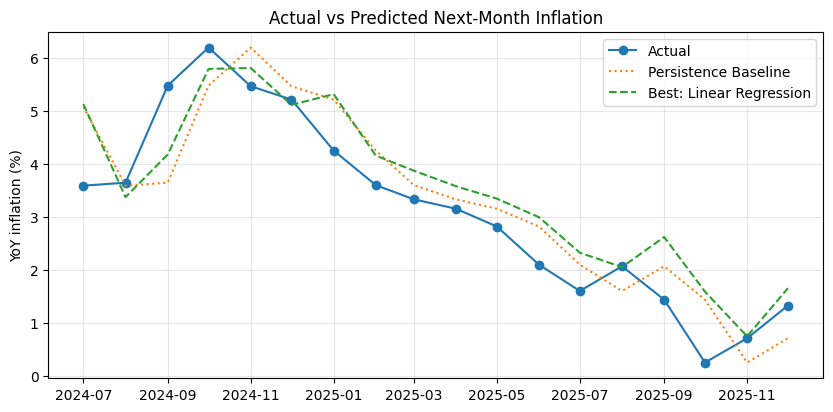

In [8]:
ml_results=results[results.Model!="Persistence Baseline"]
best=ml_results.iloc[0].Model
print("Best ML model by test RMSE:",best)
print("Beats persistence baseline:", float(ml_results.iloc[0].RMSE) < float(results.loc[results.Model=="Persistence Baseline","RMSE"].iloc[0]))

plt.plot(d_test,y_test.values,"o-",label="Actual")
plt.plot(d_test,persistence,":",label="Persistence Baseline")
plt.plot(d_test,predictions[best],"--",label=f"Best: {best}")
plt.title("Actual vs Predicted Next-Month Inflation")
plt.ylabel("YoY inflation (%)"); plt.legend(); plt.grid(alpha=.3); plt.show()


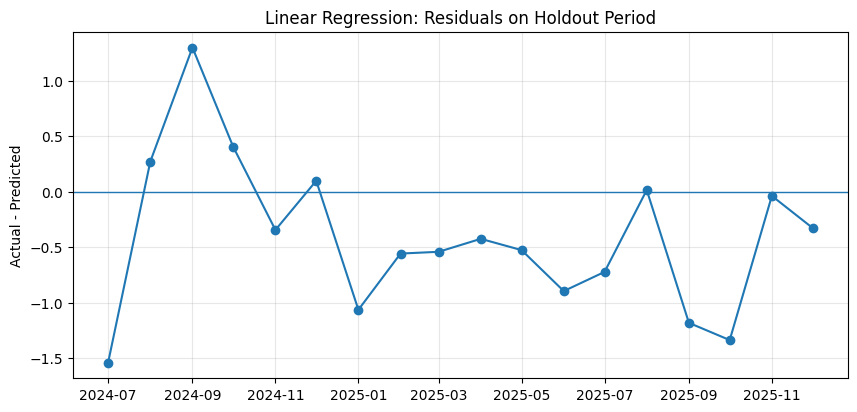

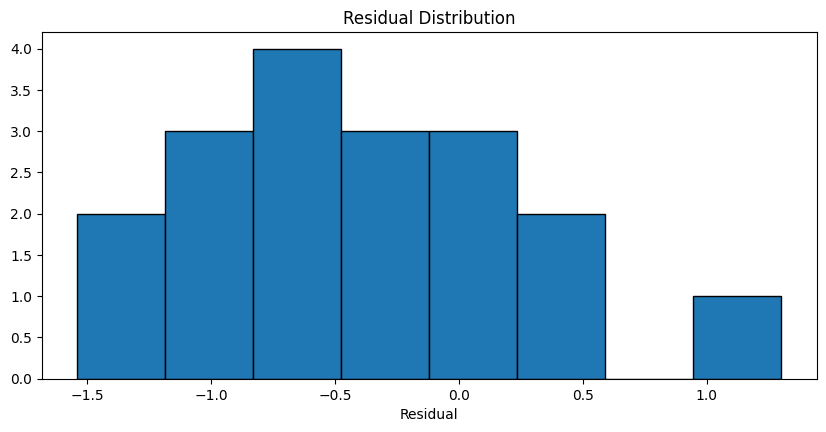

In [9]:
residuals=y_test.values-predictions[best]
plt.plot(d_test,residuals,"o-")
plt.axhline(0,lw=1)
plt.title(f"{best}: Residuals on Holdout Period")
plt.ylabel("Actual - Predicted"); plt.grid(alpha=.3); plt.show()

plt.hist(residuals,bins=8,edgecolor="black")
plt.title("Residual Distribution")
plt.xlabel("Residual"); plt.show()


## 8. Model Interpretation


,Permutation importance
change1,0.630963
infl_t,0.627966
roll3,0.310991
infl_lag2,0.208054
infl_lag1,0.101738
roll6,0.007756
cpi_mom_pct,0.005305
infl_lag12,0.004771
month_cos,0.000097
month_sin,-0.001508


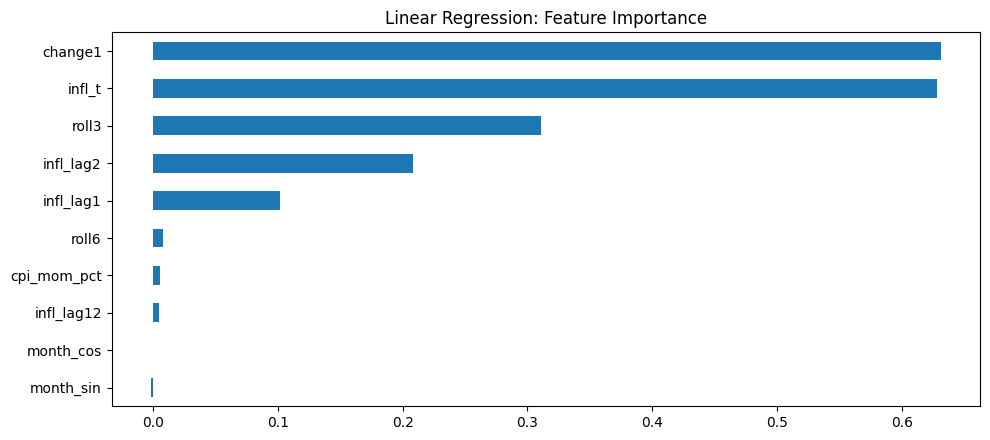

In [10]:
perm=permutation_importance(fitted[best],X_test,y_test,n_repeats=30,random_state=SEED,scoring="neg_mean_squared_error")
importance=pd.Series(perm.importances_mean,index=X.columns).sort_values()
display(importance.tail(10).sort_values(ascending=False).to_frame("Permutation importance"))
importance.tail(10).plot.barh()
plt.title(f"{best}: Feature Importance")
plt.tight_layout(); plt.show()


## 9. Final Forecast
The best-performing ML model is refitted using all labelled observations. The latest available feature row is then used to estimate the following month's inflation.

**Important:** this is an academic model forecast, not an official forecast.


In [11]:
# Rebuild the latest feature row (no target required)
latest_X=pd.DataFrame(index=d.index)
latest_X["infl_t"]=infl
for lag in [1,2,3,6,12]: latest_X[f"infl_lag{lag}"]=infl.shift(lag)
latest_X["roll3"]=infl.rolling(3).mean(); latest_X["roll6"]=infl.rolling(6).mean()
latest_X["change1"]=infl.diff(1); latest_X["cpi_mom_pct"]=d.cpi_index.pct_change()*100
latest_X["month_sin"]=np.sin(2*np.pi*latest_X.index.month/12); latest_X["month_cos"]=np.cos(2*np.pi*latest_X.index.month/12)
latest_X=latest_X[X.columns].dropna()
final_model=models[best]
final_model.fit(X,y)
forecast=float(final_model.predict(latest_X.iloc[[-1]])[0])
forecast_month=latest_X.index[-1]+pd.offsets.MonthBegin(1)
print(f"Academic forecast for {forecast_month:%B %Y}: {forecast:.2f}%")


Academic forecast for January 2026: 1.62%


## 10. Results, Challenges, Limitations and Future Scope

### Results
Use the model-comparison table above to report the best model. MAE measures average absolute error, MSE penalises larger errors, RMSE expresses error in percentage points, and R² measures explained variation. A useful ML model should also be compared with the persistence baseline.

### Challenges and Solutions
- **Time-series leakage:** solved by chronological splitting and TimeSeriesSplit.
- **CPI base revision:** the modelling dataset is kept internally consistent on the 2012=100 historical series through December 2025; the new 2024=100 series is documented but not mixed into this training column.
- **Economic shocks/outliers:** inspected but retained when they are genuine observations.
- **Small monthly sample:** model complexity is deliberately limited and a simple baseline is included.

### Limitations
- The model uses historical CPI dynamics and seasonality; it does not directly observe future food, fuel, exchange-rate or policy shocks.
- Structural changes can weaken relationships learned from the past.
- This is a one-month-ahead academic forecast, not a causal model.

### Future Scope
Future versions can add carefully lagged official variables such as IIP, policy rates and exchange-rate/commodity indicators, provided publication timing is respected to prevent leakage. ARIMA and other dedicated time-series models can also be compared as extensions.

### Conclusion
This project demonstrates a complete regression workflow on authentic Indian CPI data: validation, EDA, feature engineering, chronological splitting, multiple-model comparison, regression metrics, interpretation and forecasting.


## 11. Save Model Comparison


In [12]:
results.round(4).to_csv("InflationCast_model_comparison.csv",index=False)
print("Saved InflationCast_model_comparison.csv")


Saved InflationCast_model_comparison.csv
